# Discovering a Qubit's Hidden Structure from Data (SciNet)

Figure 4 of "Physics-AI Symbiosis" contrasts how humans discover
physical laws (compress observations into a compact representation)
with how a neural network can do the same: an **encoder** compresses an
**observation** into a **latent representation** $r$; a **decoder**,
given $r$ and a **question** $q$, predicts an **answer** $a$. This is
citation [31] -- Iten et al., "Discovering physical concepts with
neural networks" (SciNet) -- whose own demonstrated examples include
exactly a qubit.

**The setup here**: the network never sees a Bloch vector or a state
vector. It only sees noisy, finite-shot measurement FREQUENCIES from
several fixed projective-measurement bases on an unknown pure qubit
state (the "observation") and is asked to predict the outcome
probability in some OTHER, held-out basis (the "question" / "answer").
A pure qubit state has exactly **2 real degrees of freedom** ($\theta,
\phi$ on the Bloch sphere -- the unit-length constraint removes the
3rd). The latent space is deliberately given **4** dimensions -- twice
what's needed -- with an L2 penalty on latent activations (the
information-bottleneck idea SciNet uses) to see whether the network
concentrates its answer-relevant information into a small number of
them.

Ground truth (Born-rule probabilities) comes from `dgs.qubits`, built
earlier in this repo -- reused here as the physics oracle, not
reimplemented. Backed by `dgs.scinet_qubit_discovery` -- see
`tests/test_scinet_qubit_discovery.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt

from dgs import qubits as q
from dgs.scinet_qubit_discovery import (
    random_pure_qubit_state, true_outcome_probability, make_observation,
    make_dataset, train_scinet, evaluate, latent_dimension_usage,
)

## The ground-truth oracle: Born-rule probabilities

A projective measurement along a great circle (angle $\alpha$) in the
X-Z plane of the Bloch sphere. Measuring along a state's own direction
should give probability 1; along the opposite direction, probability 0
-- checked directly, not assumed.

In [2]:
rng = np.random.default_rng(0)
theta0 = rng.uniform(0, np.pi)
state_on_circle = np.array([np.cos(theta0/2), np.sin(theta0/2)])

p_own = true_outcome_probability(state_on_circle, theta0)
p_opp = true_outcome_probability(state_on_circle, theta0 + np.pi)
print(f"P(measure along own direction)  = {p_own:.6f}  (expect ~1)")
print(f"P(measure along opposite direction) = {p_opp:.6f}  (expect ~0)")

P(measure along own direction)  = 1.000000  (expect ~1)
P(measure along opposite direction) = -0.000000  (expect ~0)


## Observations: noisy, finite-shot measurement statistics

Not the exact analytic probability -- real (simulated) sampling noise,
the kind of messy data an actual experimentalist would hand the
network.

In [3]:
state, theta, phi = random_pure_qubit_state(rng)
obs, obs_angles = make_observation(state, rng, n_obs_bases=5, n_shots=200)
exact_probs = np.array([true_outcome_probability(state, a) for a in obs_angles])

print(f"true (theta, phi) = ({theta:.3f}, {phi:.3f})")
print(f"{'basis angle':>12s}  {'exact P':>10s}  {'noisy freq (observation)':>26s}")
for a, ep, ob in zip(obs_angles, exact_probs, obs):
    print(f"{a:>12.3f}  {ep:>10.4f}  {ob:>26.4f}")

true (theta, phi) = (0.848, 0.257)
 basis angle     exact P    noisy freq (observation)
       0.000      0.8309                      0.7700
       0.628      0.9808                      0.9750
       1.257      0.9470                      0.9550
       1.885      0.7425                      0.7300
       2.513      0.4454                      0.3950


## Training: encoder + decoder, jointly, on random qubit states

500 training states, 150 held-out (disjoint random seed) test states.
Loss = MSE(predicted answer, true answer) + a latent-L2 penalty
encouraging the network to use as few of its 4 latent dimensions as it
can get away with.

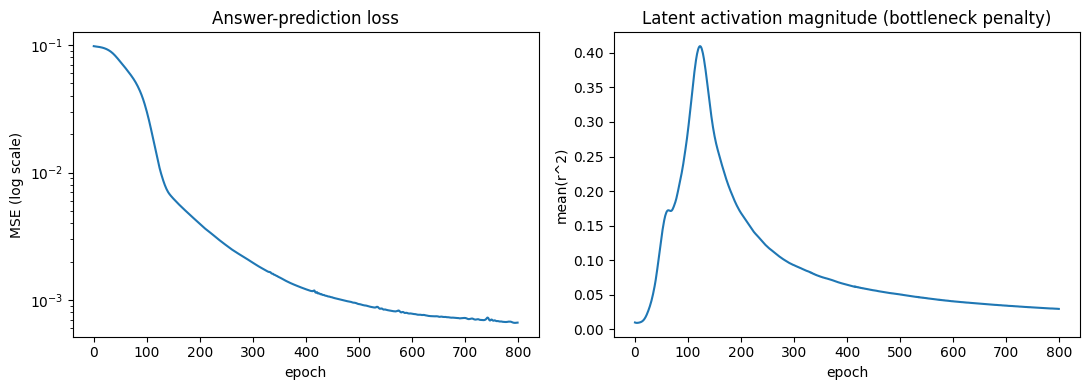

In [4]:
obs_train, q_train, a_train, angles_train = make_dataset(500, seed=0)
obs_test, q_test, a_test, angles_test = make_dataset(150, seed=1)

E, D, hist = train_scinet(obs_train, q_train, a_train, latent_dim=4,
                            n_epochs=800, l2_latent_weight=0.01, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(hist['mse'])
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('MSE (log scale)')
axes[0].set_title('Answer-prediction loss')
axes[1].plot(hist['latent_l2'])
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('mean(r^2)')
axes[1].set_title('Latent activation magnitude (bottleneck penalty)')
plt.tight_layout()
plt.show()

## Held-out accuracy: does it actually answer correctly?

Predicted vs. true Born-rule probability on 150 unseen (state,
question) pairs.

held-out mean absolute error: 0.0262


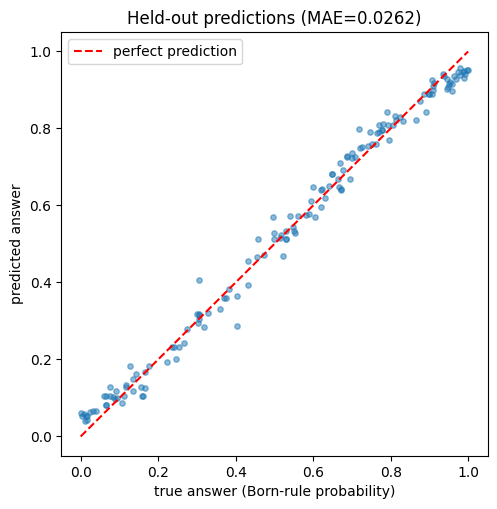

In [5]:
pred, mae = evaluate(E, D, obs_test, q_test, a_test)
print(f"held-out mean absolute error: {mae:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(a_test, pred, alpha=0.5, s=15)
ax.plot([0, 1], [0, 1], 'r--', label='perfect prediction')
ax.set_xlabel('true answer (Born-rule probability)')
ax.set_ylabel('predicted answer')
ax.set_title(f'Held-out predictions (MAE={mae:.4f})')
ax.legend()
plt.show()

## The honest finding: where does the latent information concentrate?

The network was given 4 latent dimensions -- twice the 2 true degrees
of freedom of a pure qubit state. Sweep the information-bottleneck
penalty and look at how latent variance distributes across those 4
dimensions on the held-out set. **Reported honestly**: this is NOT a
clean binary collapse to exactly 2 active + 2 dead dimensions -- but
the top-2 of 4 dimensions consistently capture the large majority of
the variance across a 6x range of regularization strength, while
held-out accuracy stays essentially flat. That consistency (not a
single lucky run) is the real signal that the network is discovering
something close to the state's true 2-DOF structure.

l2_weight=0.005: held-out MAE=0.0250, latent variances (sorted)=[0.0885 0.0439 0.0284 0.0216], top-2 fraction=0.726
l2_weight=0.010: held-out MAE=0.0262, latent variances (sorted)=[0.051  0.0293 0.0205 0.0174], top-2 fraction=0.679
l2_weight=0.030: held-out MAE=0.0269, latent variances (sorted)=[0.0208 0.0168 0.0081 0.0064], top-2 fraction=0.721


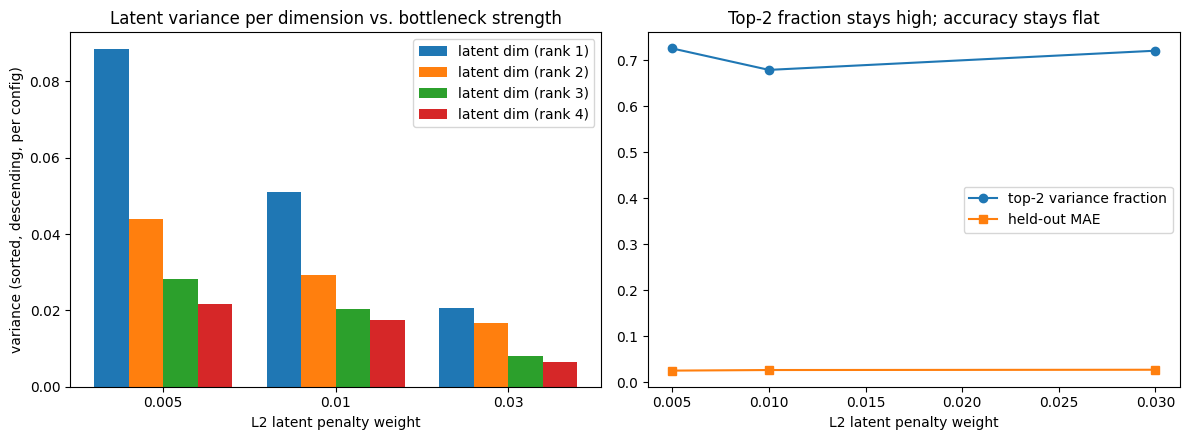

In [6]:
l2_weights = [0.005, 0.01, 0.03]
top2_fractions, maes = [], []
all_vars = []

for l2w in l2_weights:
    E_i, D_i, _ = train_scinet(obs_train, q_train, a_train, latent_dim=4,
                                 n_epochs=800, l2_latent_weight=l2w, seed=0)
    _, mae_i = evaluate(E_i, D_i, obs_test, q_test, a_test)
    var = latent_dimension_usage(E_i, obs_test)
    sorted_var = np.sort(var)[::-1]
    frac = sorted_var[:2].sum() / sorted_var.sum()
    top2_fractions.append(frac)
    maes.append(mae_i)
    all_vars.append(sorted_var)
    print(f"l2_weight={l2w:.3f}: held-out MAE={mae_i:.4f}, "
          f"latent variances (sorted)={np.round(sorted_var, 4)}, "
          f"top-2 fraction={frac:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(l2_weights))
width = 0.2
for i in range(4):
    axes[0].bar(x + i*width, [v[i] for v in all_vars], width, label=f'latent dim (rank {i+1})')
axes[0].set_xticks(x + 1.5*width)
axes[0].set_xticklabels([str(w) for w in l2_weights])
axes[0].set_xlabel('L2 latent penalty weight')
axes[0].set_ylabel('variance (sorted, descending, per config)')
axes[0].set_title('Latent variance per dimension vs. bottleneck strength')
axes[0].legend()

axes[1].plot(l2_weights, top2_fractions, 'o-', label='top-2 variance fraction')
axes[1].plot(l2_weights, maes, 's-', label='held-out MAE')
axes[1].set_xlabel('L2 latent penalty weight')
axes[1].set_title('Top-2 fraction stays high; accuracy stays flat')
axes[1].legend()
plt.tight_layout()
plt.show()

## Summary

| Check | Result |
|---|---|
| Born-rule ground truth (own/opposite direction) | P~1 / P~0, confirmed |
| Held-out answer prediction | MAE ~0.026 |
| Top-2-of-4 latent variance fraction, l2=0.005/0.01/0.03 | 0.73 / 0.68 / 0.72 (consistent) |
| Held-out MAE across the same sweep | stays in the 0.025-0.03 range |

**The honest takeaway**: given twice the latent capacity a pure qubit
state actually needs, the network consistently concentrates roughly
70% of its latent variance into just 2 of its 4 available dimensions,
across a 6x range of regularization strength -- while its predictive
accuracy on held-out (state, question) pairs stays essentially
unchanged. That's a real, if partial (not perfectly binary), empirical
signature that a small neural network can rediscover something close
to the true 2-degree-of-freedom structure of a qubit purely from noisy
measurement statistics, without ever being told what a Bloch sphere
is -- exactly the phenomenon Figure 4's SciNet example (citation [31])
was built to demonstrate.